# P281 Homework Set 4
2026-11-12 hw4_11_12_q2.ipynb Bella K

In [32]:
import numpy as np
from numpy import pi, sqrt, cos, sin, exp
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import quad
from scipy.special import jv

### Question 2
Computing Bessel functions

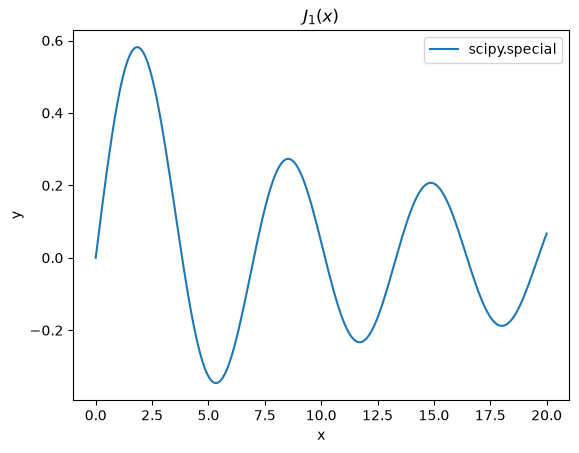

In [ ]:
xs = np.linspace(0, 20, 200)
ys_scp = jv(1, xs)

plt.plot(xs, ys_scp, label = 'scipy.special')
plt.title('$J_1(x)$')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()

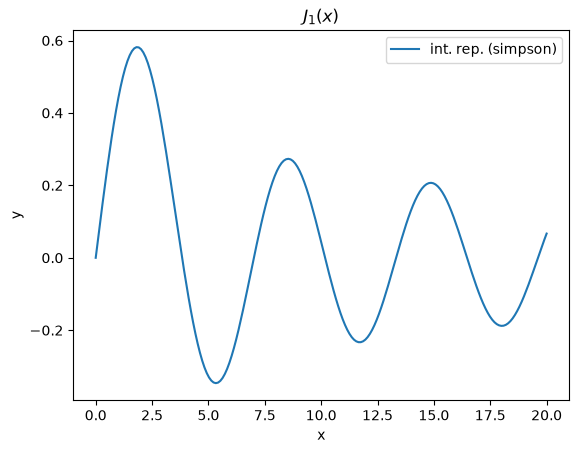

In [37]:
def simps(f, a, b, xs, nn):
    if nn % 2 == 1:
        nn = nn + 1
        print(f'Number of slices odd; adjusted to be {nn}')

    h = (b - a)/nn
    us = np.linspace(a, b, nn + 1)

    sums = np.zeros_like(xs)
    for i, x in enumerate(xs):
        fs = f(us, x)

        wts = np.ones(nn + 1)
        wts[::2] = 2 * np.ones(len(wts[::2]))
        wts[1::2] = 4 * np.ones(len(wts[1::2]))
        wts[0], wts[-1] = (1, 1)

        sums[i] = h / 3 * sum(fs * wts)
    return sums

def fun(u, x):
    return cos(u - x * sin(u))

ys_smp = 1 / pi * simps(fun, 0, pi, xs, 200)

plt.plot(xs, ys_smp, label = 'int. rep. (simpson)')
plt.title('$J_1(x)$')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()

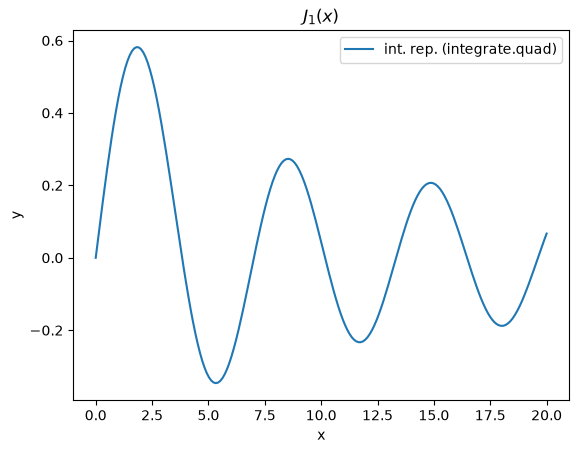

In [38]:
ys_qd = np.zeros_like(ys_scp)
for i, x in enumerate(xs):
    ys_qd[i] = 1 / pi * quad(fun, 0, pi, args = (x))[0]

plt.plot(xs, ys_qd, label = 'int. rep. (integrate.quad)')
plt.title('$J_1(x)$')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()

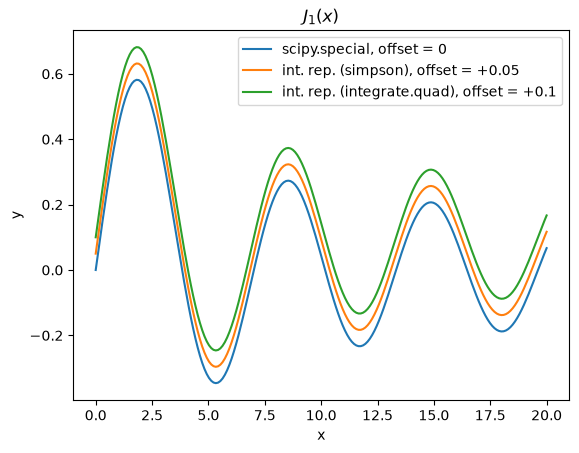

In [42]:
plt.plot(xs, ys_scp, label = 'scipy.special, offset = 0')
plt.plot(xs, ys_smp + 0.05, label = 'int. rep. (simpson), offset = +0.05')
plt.plot(xs, ys_qd + 0.1, label = 'int. rep. (integrate.quad), offset = +0.1')

plt.title('$J_1(x)$')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()